In [114]:
import pandas as pd

df = pd.read_parquet("dataset_limpio.parquet")

print(df.columns.tolist())
df.info()

['product_name', 'brands', 'categories', 'ingredients', 'nova_group', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'nutriscore_num', 'ecoscore_num', 'categoria_macro']
<class 'pandas.DataFrame'>
RangeIndex: 4686 entries, 0 to 4685
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_name        4570 non-null   str    
 1   brands              4563 non-null   str    
 2   categories          4661 non-null   str    
 3   ingredients         4601 non-null   str    
 4   nova_group          4365 non-null   Int8   
 5   allergens           3286 non-null   str    
 6   energy_kcal         4686 non-null   float64
 7   fat_100g            4686 non-null   float64
 8   saturated_fat_100g  4686 non-nul

### Empezaremos viendo posibles correlaciones lineales entre las variables 

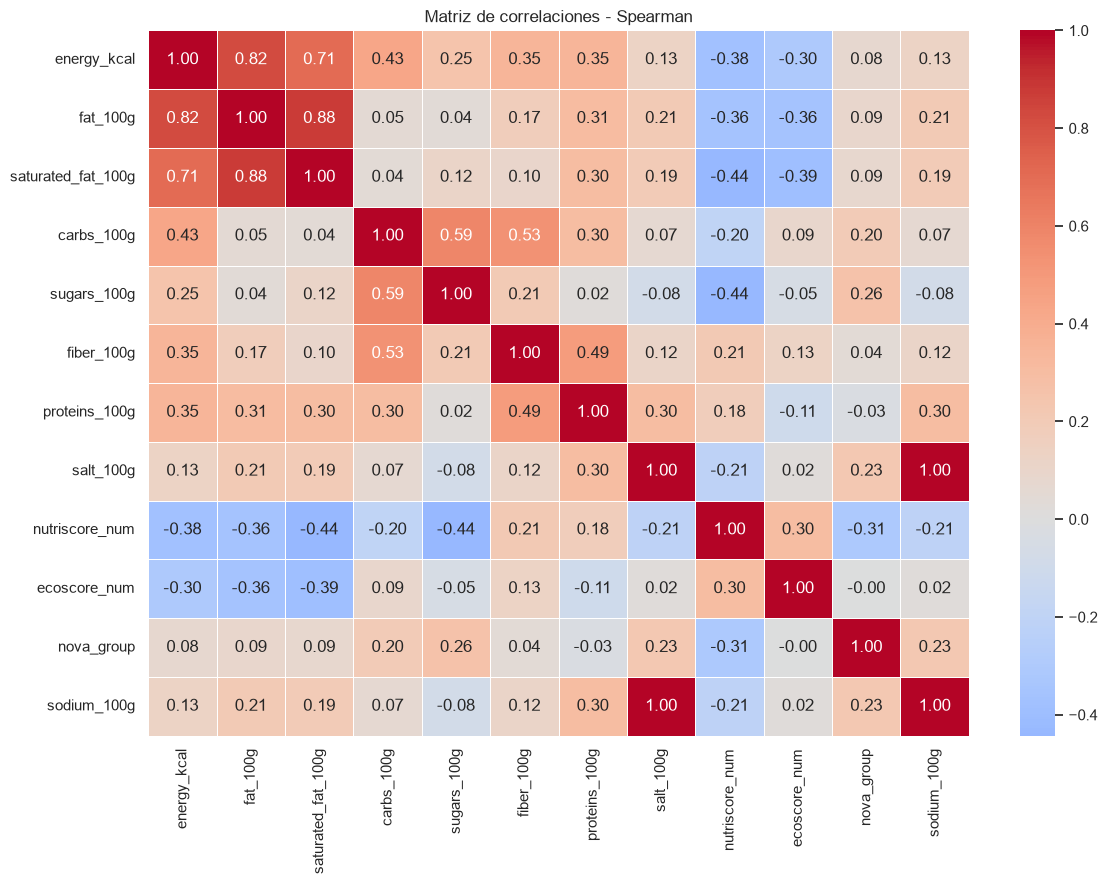

---- spearman -----
     Variable_1          Variable_2  Correlacion
95    salt_100g         sodium_100g     0.999999
14     fat_100g  saturated_fat_100g     0.880271
1   energy_kcal            fat_100g     0.824615
2   energy_kcal  saturated_fat_100g     0.706606


In [117]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

variables_corr = [
    'energy_kcal',
    'fat_100g',
    'saturated_fat_100g',
    'carbs_100g',
    'sugars_100g',
    'fiber_100g',
    'proteins_100g',
    'salt_100g',
    'nutriscore_num',
    'ecoscore_num',
    'nova_group',
    'sodium_100g'
]

corr_spearman = df[variables_corr].corr(method='spearman')
corr_pearson = df[variables_corr].corr(method='pearson')

# Extraer el triángulo superior de la matriz para evitar pares duplicados (A-B y B-A) y la diagonal (A-A)
upper_tri_spearman = corr_spearman.where(np.triu(np.ones(corr_spearman.shape), k=1).astype(bool))

# Convertir a formato tabla
corr_pairs_spearman = upper_tri_spearman.stack().reset_index()
corr_pairs_spearman.columns = ['Variable_1', 'Variable_2', 'Correlacion']

# Filtrar por valor absoluto > 0.75 y ordenar
high_corr_spearman = corr_pairs_spearman[corr_pairs_spearman['Correlacion'].abs() > 0.70].sort_values(by='Correlacion', key=abs, ascending=False)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de correlaciones - Spearman')
plt.tight_layout()
plt.show()


print("---- spearman -----")
print(high_corr_spearman)

### Podemos observar que el sodio y las sales van muy de la mano, al igual que las grasas y las grasas saturadas. Esto es información redundante que solo añade ruido al modelo, por lo que solo tendremos en cuenta sales y grasas

In [118]:
# Strip standard whitespace and hidden unicode spaces
df.columns = df.columns.str.replace("\xa0", "").str.strip()

# Drop the target columns
df = df.drop(["sodium_100g", "saturated_fat_100g"], axis=1, errors="ignore")

## Procederemos a hacer un PCA para poder analizar relaciones en una menor dimension, entre nuestras nuevas 7 variables de estudio

In [125]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

variables_nutricionales = [
    'energy_kcal', 'fat_100g', 'carbs_100g', 'sugars_100g', 
    'fiber_100g', 'proteins_100g', 'salt_100g'
]

df_pca = df[variables_nutricionales].dropna().copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca)

pca = PCA(n_components=5)
componentes = pca.fit_transform(X_scaled)

varianza_explicada = pca.explained_variance_ratio_

print('Varianza explicada por componente:')
print(varianza_explicada)

print('\nVarianza acumulada:')
print(varianza_explicada.cumsum())

Varianza explicada por componente:
[0.30485114 0.21546055 0.18312877 0.14069598 0.09085   ]

Varianza acumulada:
[0.30485114 0.52031169 0.70344047 0.84413644 0.93498645]


In [126]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=variables_nutricionales,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
)

print(loadings)

                    PC1       PC2       PC3       PC4       PC5
energy_kcal    0.612690  0.249240 -0.196550  0.083672  0.002384
fat_100g       0.386515  0.557092 -0.369735  0.017721 -0.097014
carbs_100g     0.440599 -0.527691  0.070092  0.083336  0.028998
sugars_100g    0.319719 -0.538800 -0.320066  0.060534  0.228612
fiber_100g     0.331313 -0.043039  0.586738 -0.017463 -0.665913
proteins_100g  0.236013  0.235312  0.609993  0.026487  0.701413
salt_100g     -0.115752  0.039254  0.030915  0.990489 -0.045375


### Vemos que la combinación lineal de los 3 primeros componentes esta muy distrubuida entre varias variables y recien con 4 componentes llegamos a una buena cifra de varianza explicada; y además esta 4ta componente esta prácticamente explicada por el coeficiente de las sales

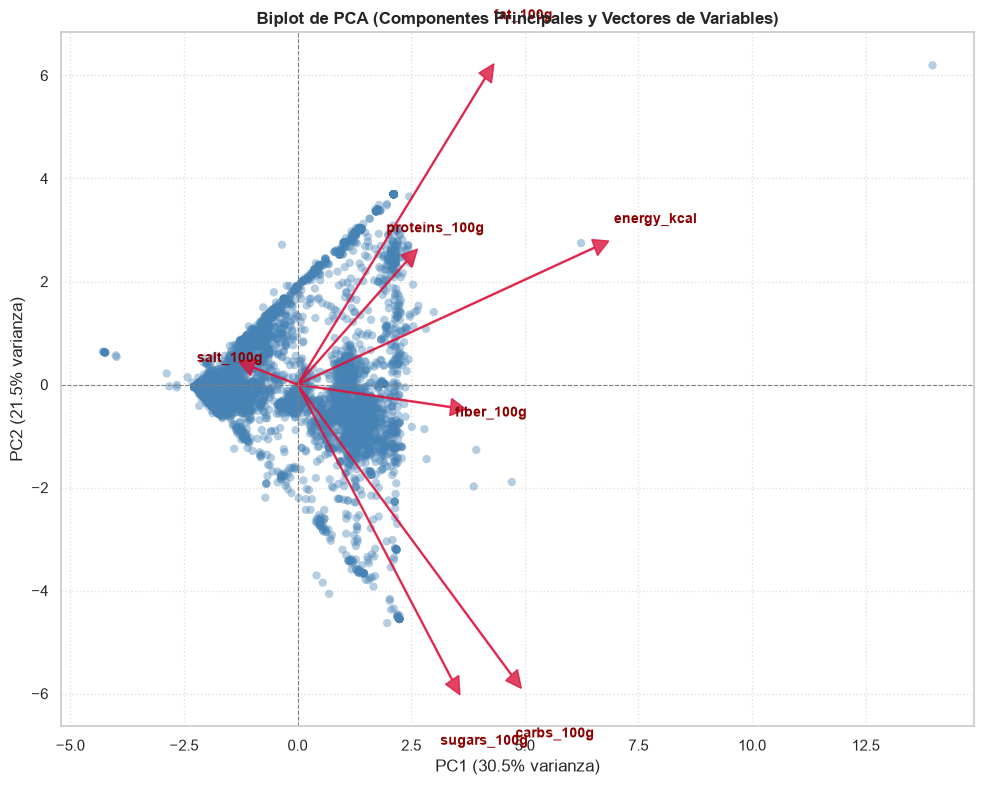

In [127]:
# graficamos para ver mejor las relaciones
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

loadings = pca.components_

plt.figure(figsize=(10, 8))

plt.scatter(
    componentes[:, 0],
    componentes[:, 1],
    alpha=0.4,
    color="steelblue",
    edgecolors="none",
    label="Observaciones",
)

scale_factor = np.max(np.abs(componentes[:, :2])) * 0.8

for i, variable in enumerate(variables_nutricionales):
    x_vec = loadings[0, i] * scale_factor
    y_vec = loadings[1, i] * scale_factor

    plt.arrow(
        0,
        0,
        x_vec,
        y_vec,
        color="crimson",
        alpha=0.8,
        width=scale_factor * 0.002,
        head_width=scale_factor * 0.03,
        head_length=scale_factor * 0.03,
        length_includes_head=True,
    )

    plt.text(
        x_vec * 1.15,
        y_vec * 1.15,
        variable,
        color="darkred",
        weight="bold",
        fontsize=10,
        ha="center",
        va="center",
    )

var_exp = pca.explained_variance_ratio_
plt.xlabel(f"PC1 ({var_exp[0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({var_exp[1]*100:.1f}% varianza)")
plt.title(
    "Biplot de PCA (Componentes Principales y Vectores de Variables)",
    fontsize=12,
    weight="bold",
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()

plt.show()

### sabemos que al hacer combinaciones lineales, aquellas variables que forman angulos rectos son aquellas que no están relacionadas entre sí. En este caso parece que tenemos 4 dimensiones independientes:
- azucares y carbohidratos
- fibras
- proteinas, energia_kilocalorias y grasas
- sales
(todas cada 100 gramos)
### Las variables dentro de un mismo grupo aportan información redundante, mientras que la ortogonalidad entre grupos demuestra que capturan perfiles nutricionales distintos

## En este punto nos parece intersante también poder ver otro tipo de relaciones, por ejemplo, sabemos que en la realidad los productos con soja suelen tener un impacto ambiental negativo, por lo que queremos ver si nos encontramos con algo de eso en los datos

In [ ]:
df_eco_soja = df[['ecoscore_num', 'contains_soy']].copy()

df_eco_soja = df_eco_soja.dropna()

print("Registros disponibles:", len(df_eco_soja))

Registros disponibles: 4686


In [130]:
tabla = pd.crosstab(
    df_eco_soja['contains_soy'],
    df_eco_soja['ecoscore_num']
)

tabla.index = ['Sin soja', 'Con soja']

display(tabla)

ecoscore_num,1,2,3,4,5
Sin soja,352,546,505,750,703
Con soja,139,145,124,123,95


### Podemos observar como a medida que mejor impacto ambiental tienen los productos, menor en la cantidad de productos con soja

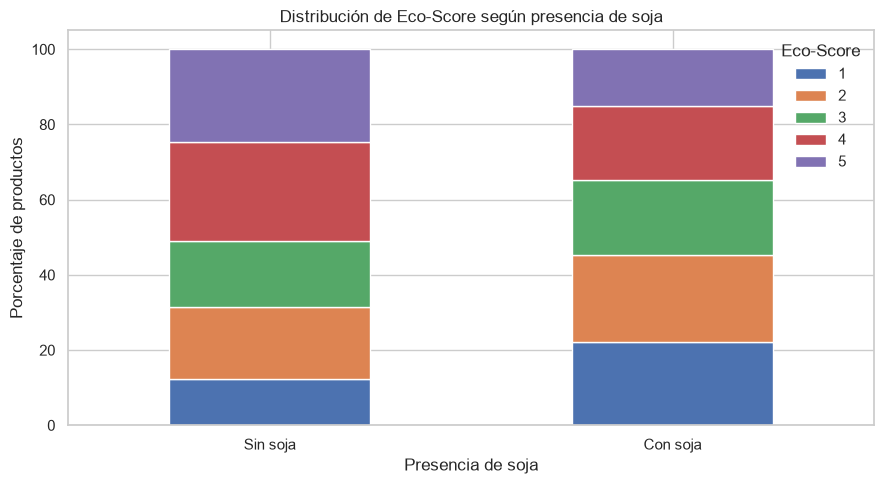

In [132]:
tabla_porcentajes = pd.crosstab(
    df_eco_soja['contains_soy'],
    df_eco_soja['ecoscore_num'],
    normalize='index'
) * 100
tabla_porcentajes.index = ['Sin soja', 'Con soja']

tabla_porcentajes.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Distribución de Eco-Score según presencia de soja')
plt.xlabel('Presencia de soja')
plt.ylabel('Porcentaje de productos')
plt.legend(title='Eco-Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


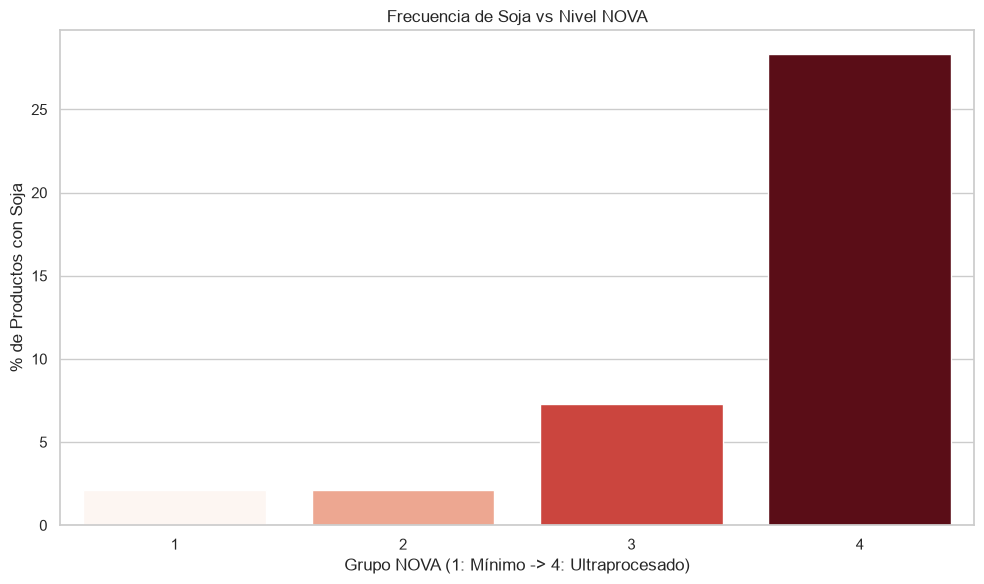

In [141]:

fig, ax = plt.subplots(figsize=(10, 6))

soja_por_nova = df.groupby('nova_group')['contains_soy'].mean() * 100

sns.barplot(
    x=soja_por_nova.index, 
    y=soja_por_nova.values, 
    hue=soja_por_nova.index, 
    palette='Reds', 
    legend=False,
    ax=ax
)

ax.set_title('Frecuencia de Soja vs Nivel NOVA')
ax.set_xlabel('Grupo NOVA (1: Mínimo -> 4: Ultraprocesado)')
ax.set_ylabel('% de Productos con Soja')

plt.tight_layout()
plt.show()

## Sin embargo,a este punto parece que estamos llegando a conclusiones muy estrictas y no estamos viendo verdaderas relaciones. Por lo que una buena idea es plantearse otra estrategia que nos permita ver más relaciones, como un clusteing. Para ello necesitamos saber cual puede ser un buen número de cluster, por lo que haremos el gráfico del codo

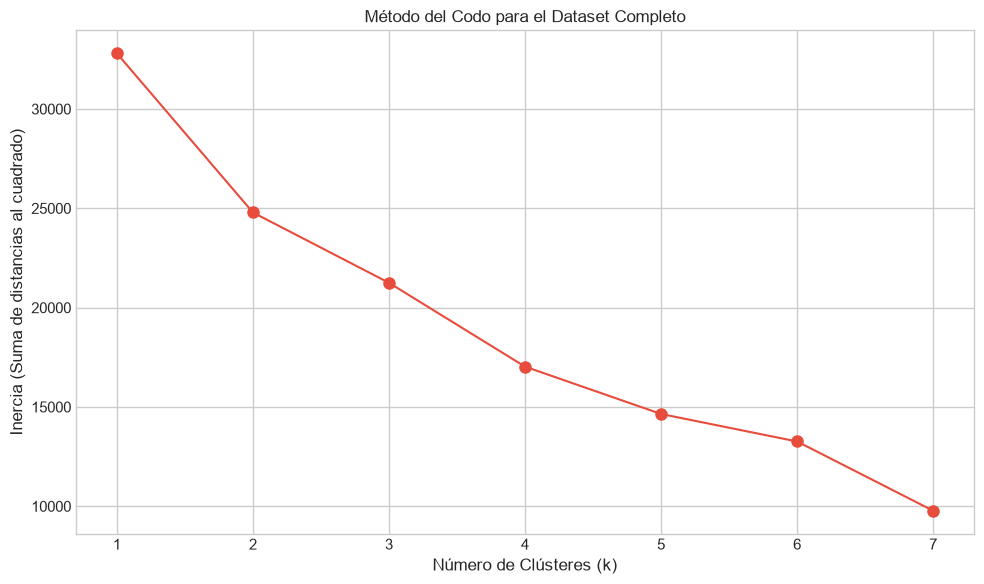

In [135]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inercia = []
rango_k = range(1, 8)

for k in rango_k:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans_temp.fit(X_scaled)
    inercia.append(kmeans_temp.inertia_)

plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))
plt.plot(rango_k, inercia, marker='o', linestyle='-', color='#e74c3c', markersize=8)
plt.title('Método del Codo para el Dataset Completo')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Inercia (Suma de distancias al cuadrado)')
plt.xticks(rango_k)
plt.tight_layout()
plt.show()

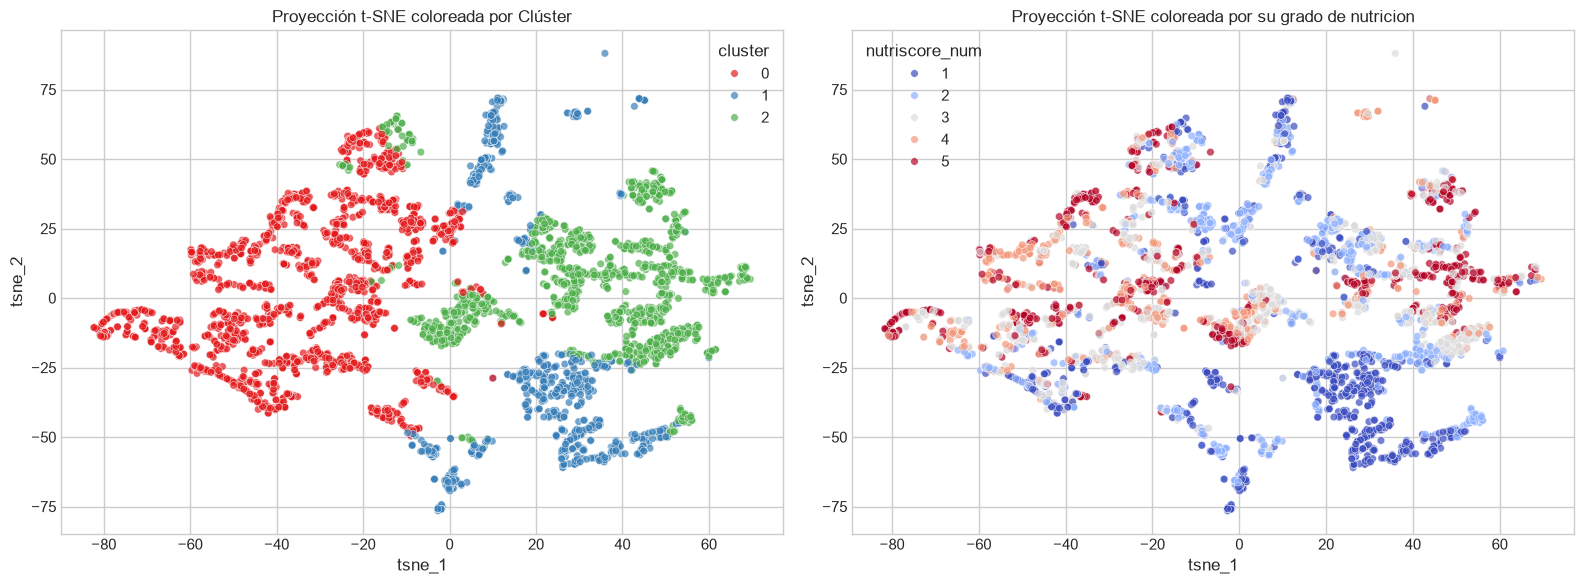

In [136]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

df_model = df.copy()

n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
df_model['cluster'] = kmeans.fit_predict(X_scaled)


tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(X_scaled)

df_model['tsne_1'] = tsne_results[:, 0]
df_model['tsne_2'] = tsne_results[:, 1]


plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_model, x='tsne_1', y='tsne_2', 
    hue='cluster', palette='Set1', alpha=0.7, s=30
)
plt.title('Proyección t-SNE coloreada por Clúster')

plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df_model, x='tsne_1', y='tsne_2', 
    hue='nutriscore_num', palette='coolwarm', alpha=0.7, s=30
)
plt.title('Proyección t-SNE coloreada por su grado de nutricion')
plt.tight_layout()
plt.show()


## Gracias a esto obervamos que parecieran exitir algunas relaciones entre los diferentes productos y el grado de nutrición de cada uno, como ocurre con el cluster de la esquina inferior derecha (donde vemos un conjunto de alimentos de características similares que son poco nutritivos). Sin embargo, no se nos deja muy en claro cual es su relación, debido a que tenemos productos de muchos tipos. Es por esto que vamos a intentar buscar relaciones entre productos de un mismo tipo usando la columna categoria_macro que generamos en la limpieza

In [ ]:
import math

def visualizar_tsne_nutricional(df, categoria_macro, variables_nutricionales, cant_clusters, perplexidad):
    df_cat = df[df['categoria_macro'] == categoria_macro].copy()
    n_muestras = len(df_cat)
    
    if n_muestras < 15:
        print(f"La categoría '{categoria_macro}' tiene pocas muestras ({n_muestras}).")
        return
        
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_cat[variables_nutricionales])
    
    kmeans = KMeans(n_clusters=cant_clusters, random_state=42, n_init='auto')
    df_cat['cluster'] = kmeans.fit_predict(X_scaled)
    df_cat['cluster_label'] = df_cat['cluster'].apply(lambda x: f"Clúster {x}")
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexidad)
    tsne_res = tsne.fit_transform(X_scaled)
    df_cat['tsne_1'] = tsne_res[:, 0]
    df_cat['tsne_2'] = tsne_res[:, 1]
    
    graficos_a_dibujar = ['cluster_label'] + variables_nutricionales
    n_graficos = len(graficos_a_dibujar)
    
    columnas = 4 
    filas = math.ceil(n_graficos / columnas)
    
    paletas = {
        'cluster_label': 'Set1', 
        'energy_kcal': 'inferno',  
        'fat_100g': 'YlOrBr',        
        'carbs_100g': 'Purples',    
        'sugars_100g': 'Blues',      
        'fiber_100g': 'Greens',
        'proteins_100g': 'Reds',     
        'salt_100g': 'bone_r',       
        'nutriscore_num': 'coolwarm' 
    }
    
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * 5, filas * 5))
    axes = axes.flatten() # Aplanar matriz para iterar fácilmente
    
    fig.suptitle(f"Perfil Espacial (t-SNE): {categoria_macro}", fontsize=20, weight='bold', y=1.02)

    # 5. Bucle de graficado
    for idx, var in enumerate(graficos_a_dibujar):
        # Asignar paleta (usa 'viridis' por defecto si no está en el diccionario)
        color_map = paletas.get(var, 'viridis')
        
        sns.scatterplot(
            data=df_cat, x='tsne_1', y='tsne_2', 
            hue=var, palette=color_map, s=40, alpha=0.8, ax=axes[idx]
        )
        
        # Títulos limpios
        titulo = "Clústeres KMeans" if var == 'cluster_label' else var.replace('_100g', ' (g)').replace('_', ' ').title()
        axes[idx].set_title(titulo, fontsize=14, weight='bold')
        axes[idx].set_xlabel('')
        axes[idx].set_ylabel('')

    # 6. Apagar los gráficos vacíos (si sobran espacios en la cuadrícula)
    for vacio_idx in range(n_graficos, len(axes)):
        axes[vacio_idx].axis('off')

    plt.tight_layout()
    plt.show()

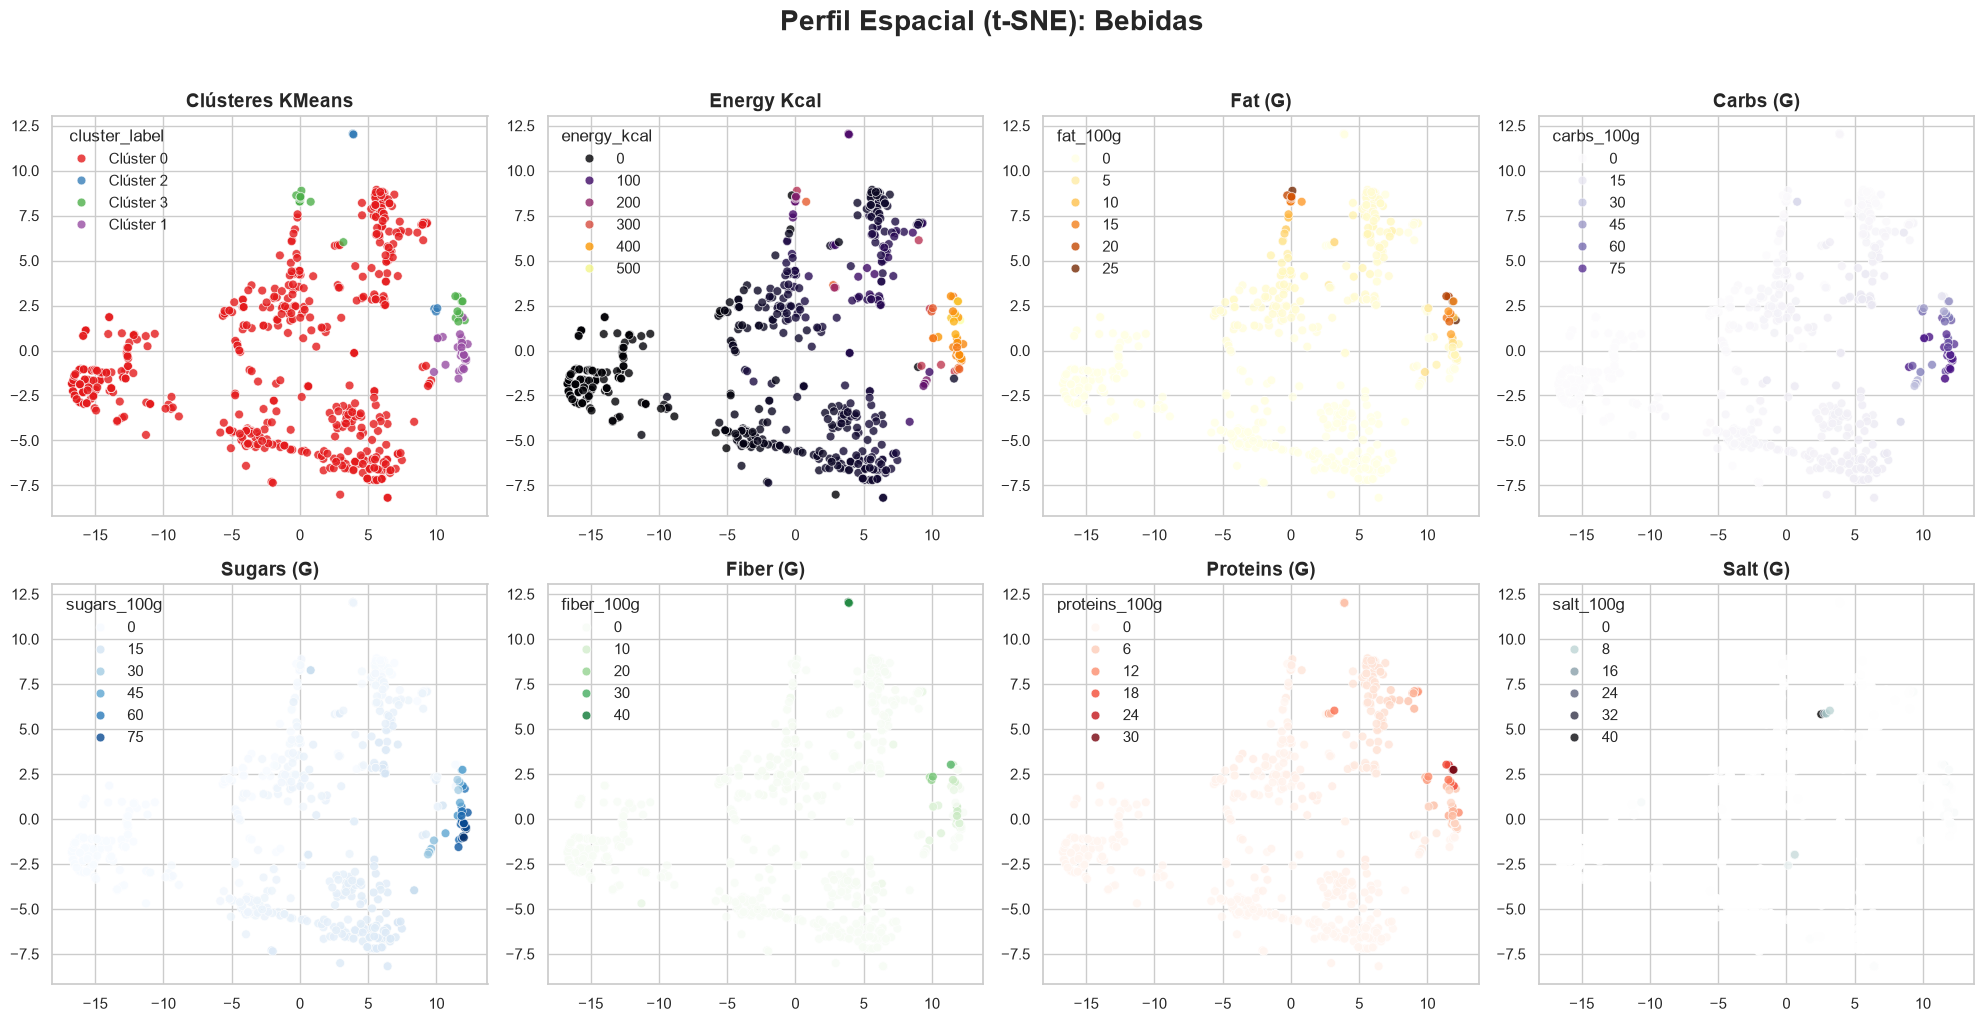

In [155]:
visualizar_tsne_nutricional(df, "Bebidas", variables_nutricionales, 4, 80)

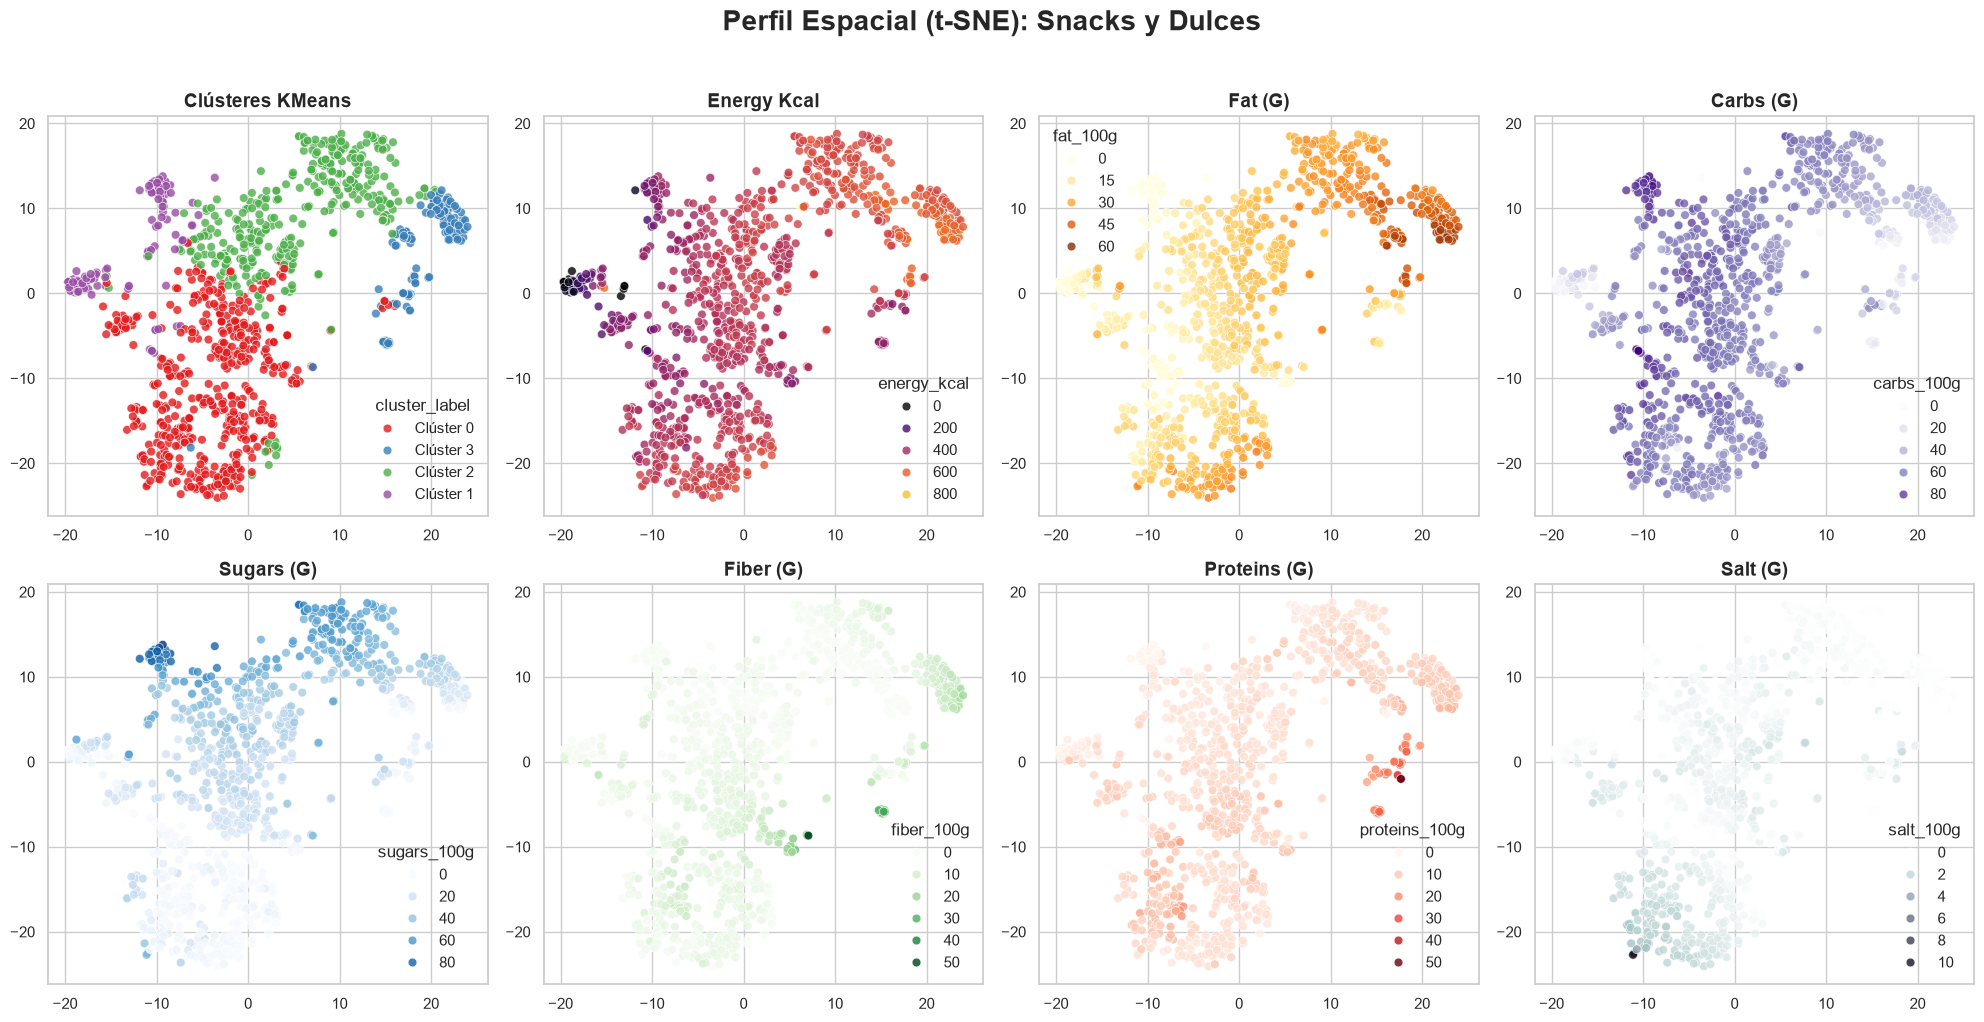

In [156]:
visualizar_tsne_nutricional(df, "Snacks y Dulces", variables_nutricionales, 4, 80)

### Con estos gráficos podemos llegar a apreciar ciertas relaciones, que nos sugieren algunas hipótesis que podríamos plantear
- Bebidas: Existe un segmento de bebidas caracterizado por una elevada concentración de azúcares y carbohidratos, con un aporte reducido de proteínas y fibra, que presenta un perfil nutricional desfavorable frente a otros tipos de bebidas. (poco valor de mercado)
- Snacks: Dentro de los snacks existen productos con un aporte elevado de proteínas o fibra que, simultáneamente, presentan concentraciones importantes de grasas y energía, por lo que un perfil nutricional aparentemente favorable en ciertos nutrientes no necesariamente implica una mejor calidad nutricional global. (mejor valor de mercado)

### Volvamos a analizar el caso de la soja que vimos anteriormente

In [ ]:
variables_contexto = ['contains_soy', 'nova_group', 'nutriscore_num', 'ecoscore_num']

visualizar_tsne_nutricional()

Total de productos tras la limpieza: 3130


In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[variables_nutricionales])

kmeans = KMeans(n_clusters=4, random_state=25, n_init=50)
df_clean['cluster'] = kmeans.fit_predict(X_scaled)

tsne = TSNE(n_components=2, perplexity=40, random_state=52)
X_tsne = tsne.fit_transform(X_scaled)
df_clean['tsne_1'] = X_tsne[:, 0]
df_clean['tsne_2'] = X_tsne[:, 1]

print("Clustering y reducción de dimensionalidad completados.")

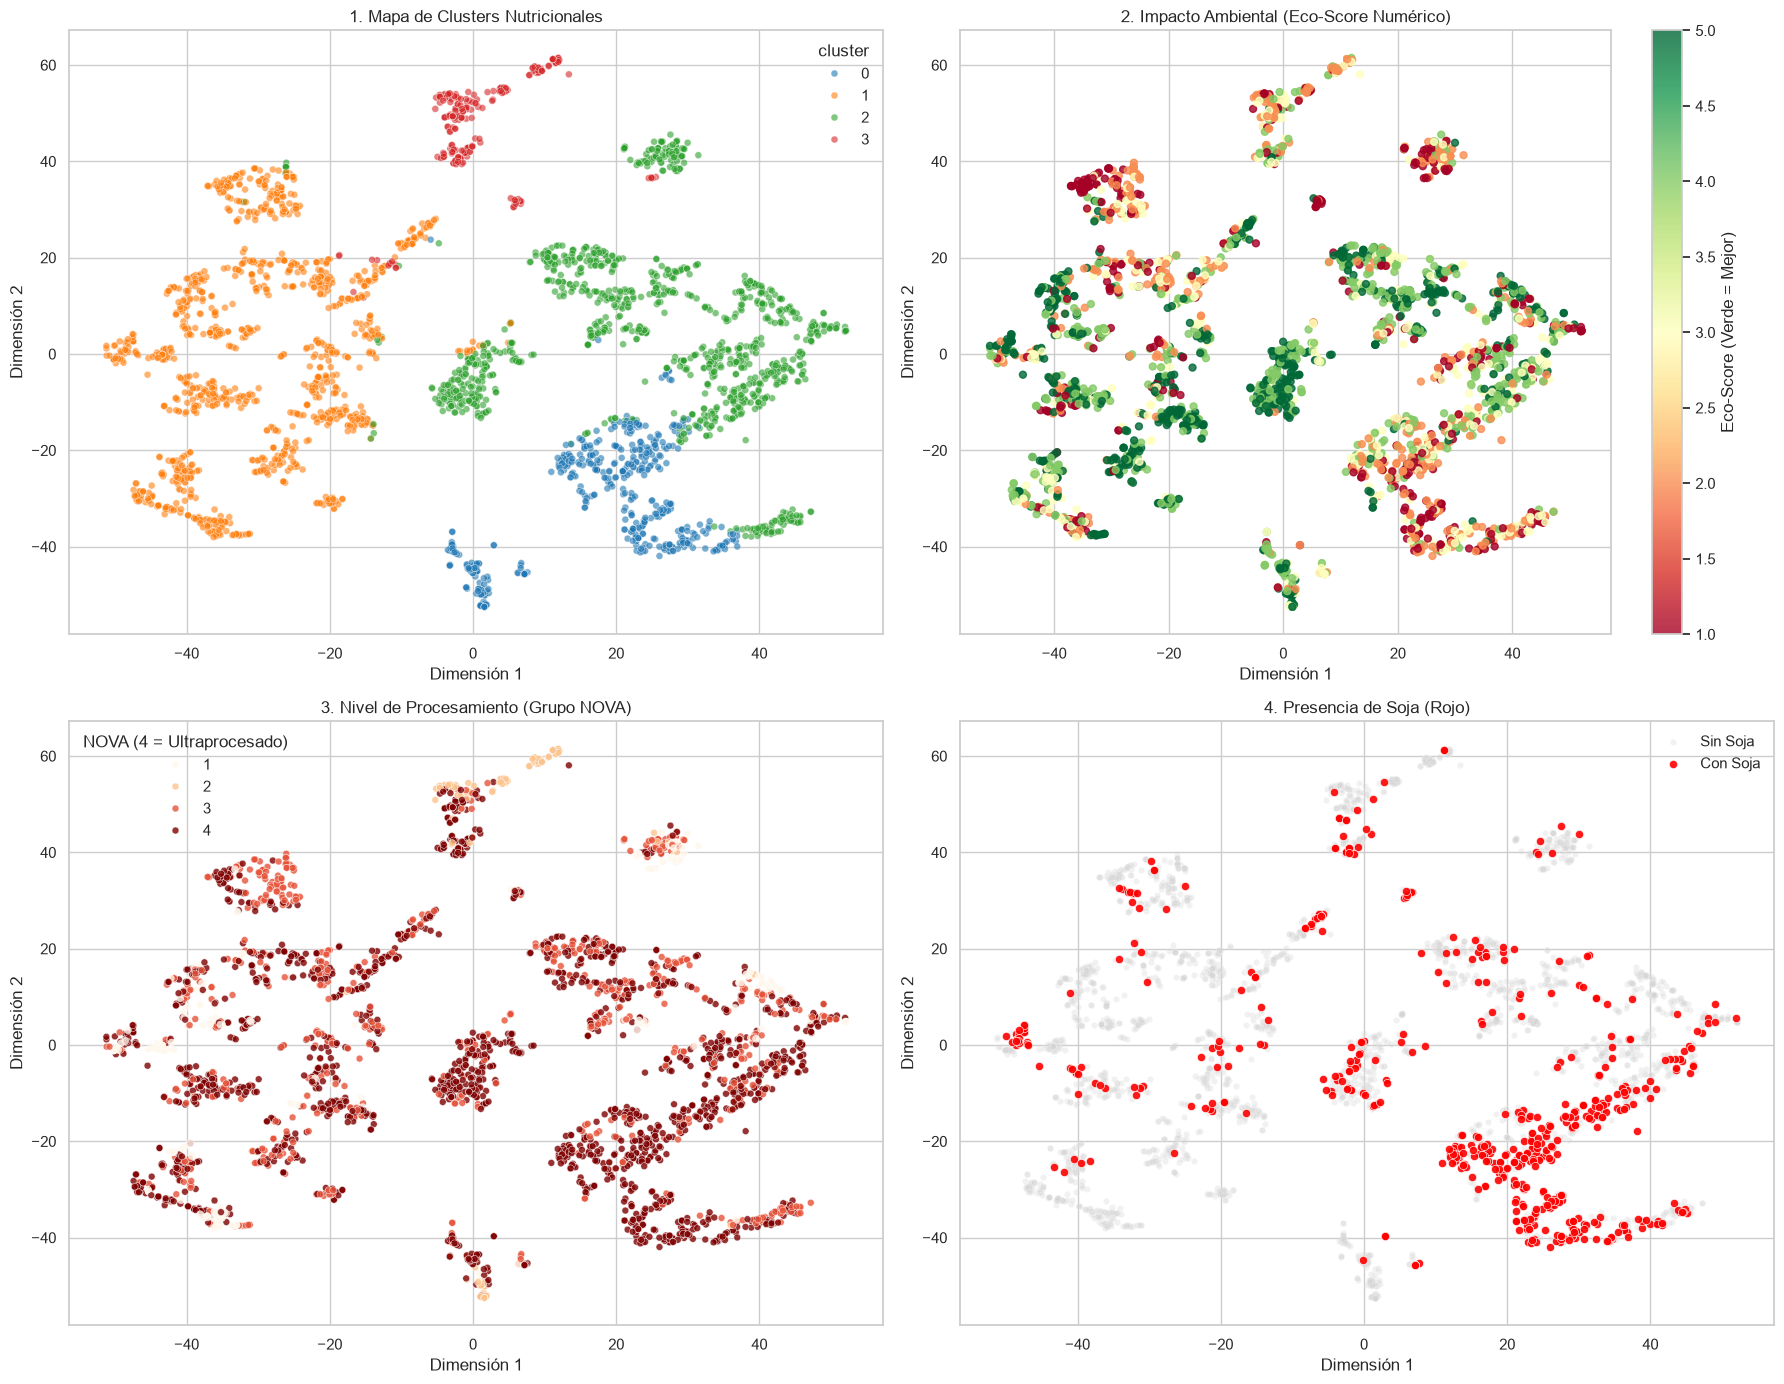

In [133]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

axes = axes.flatten()

sns.scatterplot(
    data=df_clean, x='tsne_1', y='tsne_2', 
    hue='cluster', palette='tab10', alpha=0.6, s=25, ax=axes[0]
)
axes[0].set_title('1. Mapa de Clusters Nutricionales')
axes[0].set_xlabel('Dimensión 1')
axes[0].set_ylabel('Dimensión 2')


scatter_eco = axes[1].scatter(
    df_clean['tsne_1'], df_clean['tsne_2'], 
    c=df_clean['ecoscore_num'], cmap='RdYlGn', alpha=0.8, s=25
)
axes[1].set_title('2. Impacto Ambiental (Eco-Score Numérico)')
plt.colorbar(scatter_eco, ax=axes[1], label='Eco-Score (Verde = Mejor)')
axes[1].set_xlabel('Dimensión 1')
axes[1].set_ylabel('Dimensión 2')

sns.scatterplot(
    data=df_clean, x='tsne_1', y='tsne_2', 
    hue='nova_group', palette='OrRd', alpha=0.8, s=25, ax=axes[2]
)
axes[2].set_title('3. Nivel de Procesamiento (Grupo NOVA)')
axes[2].legend(title='NOVA (4 = Ultraprocesado)')
axes[2].set_xlabel('Dimensión 1')
axes[2].set_ylabel('Dimensión 2')

sns.scatterplot(
    data=df_clean[~df_clean['contains_soy']], 
    x='tsne_1', y='tsne_2', color='lightgrey', alpha=0.3, s=20, label='Sin Soja', ax=axes[3]
)
sns.scatterplot(
    data=df_clean[df_clean['contains_soy']], 
    x='tsne_1', y='tsne_2', color='red', alpha=0.9, s=35, label='Con Soja', ax=axes[3]
)
axes[3].set_title('4. Presencia de Soja (Rojo)')
axes[3].legend()
axes[3].set_xlabel('Dimensión 1')
axes[3].set_ylabel('Dimensión 2')

plt.tight_layout()
plt.show()

### Esto nos podría llegar a sugerir una posible separación de productos donde la soja es solo un aditivo vegetal, y otros donde se ultra procesa a fin de sacarle el máximo partido a nivel económico, a costa de un impacto ambiental mayor. Sin embargo, tampoco hay que toamrlo a la ligera, sino que es uns posible conclusión (hipótesis) a demostrar

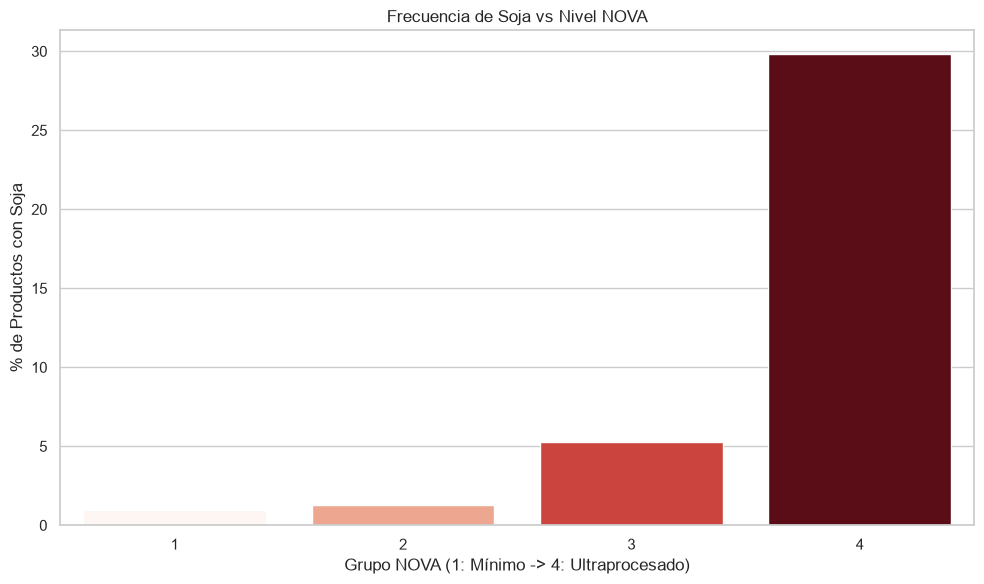

In [134]:

fig, ax = plt.subplots(figsize=(10, 6))

soja_por_nova = df_clean.groupby('nova_group')['contains_soy'].mean() * 100

sns.barplot(
    x=soja_por_nova.index, 
    y=soja_por_nova.values, 
    hue=soja_por_nova.index, 
    palette='Reds', 
    legend=False,
    ax=ax
)

ax.set_title('Frecuencia de Soja vs Nivel NOVA')
ax.set_xlabel('Grupo NOVA (1: Mínimo -> 4: Ultraprocesado)')
ax.set_ylabel('% de Productos con Soja')

plt.tight_layout()
plt.show()

In [ ]:
def analizar_categoria_tsne(df, categoria_macro, variables_nutricionales):
    """
    Filtra el dataset por categoría, estandariza, aplica KMeans y t-SNE, 
    y grafica los resultados.
    """
    print(f"\nAnalizando la categoría: {categoria_macro}...")
    
    # 1. Filtrar y copiar
    df_cat = df[df['categoria_macro'] == categoria_macro].copy()
    n_muestras = len(df_cat)
    
    if n_muestras < 15:
        print(f"La categoría '{categoria_macro}' tiene muy pocas muestras ({n_muestras}) para clustering significativo.")
        return
        
    # 2. Preprocesamiento
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_cat[variables_nutricionales])
    
    # 3. Clustering (Ajustar K si hay muy pocas muestras)
    k_clusters = 4 if n_muestras > 50 else 2
    kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init='auto')
    df_cat['cluster'] = kmeans.fit_predict(X_scaled)
    df_cat['cluster_label'] = df_cat['cluster'].apply(lambda x: f"Clúster {x}")
    
    # 4. t-SNE con Perplejidad Dinámica (Evita errores en categorías pequeñas)
    # La perplejidad recomendada es N/3, topando en 30 o 50.
    perp_dinamica = min(50, max(5, n_muestras // 3)) 
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=perp_dinamica)
    tsne_res = tsne.fit_transform(X_scaled)
    df_cat['tsne_1'] = tsne_res[:, 0]
    df_cat['tsne_2'] = tsne_res[:, 1]
    
    # 5. Visualización
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 3, figsize=(24, 14))
    fig.suptitle(f"Análisis Multivariado: {categoria_macro} (N={n_muestras})", fontsize=20, weight='bold')

    sns.scatterplot(data=df_cat, x='tsne_1', y='tsne_2', hue='cluster_label', palette='Set1', s=60, alpha=0.8, ax=axes[0, 0])
    axes[0, 0].set_title('Clústeres KMeans')

    sns.scatterplot(data=df_cat, x='tsne_1', y='tsne_2', hue='nutriscore_num', palette='coolwarm', s=60, alpha=0.8, ax=axes[0, 1])
    axes[0, 1].set_title('Grado de Nutrición (Nutriscore)')

    sns.scatterplot(data=df_cat, x='tsne_1', y='tsne_2', hue='sugars_100g', palette='Blues', s=60, alpha=0.8, ax=axes[0, 2])
    axes[0, 2].set_title('Azúcares (g/100g)')

    sns.scatterplot(data=df_cat, x='tsne_1', y='tsne_2', hue='carbs_100g', palette='Greens', s=60, alpha=0.8, ax=axes[1, 0])
    axes[1, 0].set_title('Carbohidratos (g/100g)')

    sns.scatterplot(data=df_cat, x='tsne_1', y='tsne_2', hue='energy_kcal', palette='inferno', s=60, alpha=0.8, ax=axes[1, 1])
    axes[1, 1].set_title('Energía (Kcal)')

    # Extra: Si tienes grasa o proteína, podrías usar este eje en lugar de apagarlo
    axes[1, 2].axis('off') 

    plt.tight_layout()
    plt.show()

In [ ]:
analizar_categoria_tsne(df, "Vegetales y Cereales", variables_nutricionales=variables_nutricionales)

# Con todo este análisis podriamos plantearnos una hipótesis para ver si existe una relación entre la soja y un ecoscore negativo ocasionado por la alta industrialización que lleva por detras